In [1]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import regularizers

In [2]:
!pip install git+https://github.com/tensorflow/docs

  Cloning https://github.com/tensorflow/docs to /tmp/pip-req-build-p62aaf4k
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs /tmp/pip-req-build-p62aaf4k
  Resolved https://github.com/tensorflow/docs to commit d599803bd2a79835ae9624312cf4ae3c0b4948e4
  Preparing metadata (setup.py) ... done
  Created wheel for tensorflow-docs: filename=tensorflow_docs-2026.10.5.42568-py3-none-any.whl size=187306 sha256=8e904db448ddf3df2a18319dd69c8cab171bed49ebdf88585b205e4908cec97e
  Stored in directory: /tmp/pip-ephem-wheel-cache-ed83rbnz/wheels/39/8c/ee/7878694b49afbe0a211a2374ea6aa9c4ffc173d08880bae11f
Successfully built tensorflow-docs


In [3]:
import tensorflow_docs as tfdocs
import tensorflow_docs.modeling
import tensorflow_docs.plots

In [4]:
from matplotlib import pyplot as plt
import numpy as np
import pathlib
import shutil
import tempfile

In [5]:
logdir = pathlib.Path(tempfile.mkdtemp())/"tensorboard_logs"
shutil.rmtree(logdir,ignore_errors=True)

ZBIÓR DANYCH HIGGSA

In [6]:
gz = tf.keras.utils.get_file('HIGGS.csv.gz','https://archive.ics.uci.edu/ml/machine-learning-databases/00280/HIGGS.csv.gz')

2815852544/Unknown 175s 0us/step

In [7]:
FEATURES = 28

In [8]:
ds = tf.data.experimental.CsvDataset(gz,[float()]*(FEATURES+1),compression_type="GZIP")

In [9]:
def pack_row(*row):
  label = row[0]
  features = tf.stack(row[1:],1)
  return features, label

In [10]:
packed_ds = ds.batch(10000).map(pack_row).unbatch()

tf.Tensor(
[ 0.8692932  -0.6350818   0.22569026  0.32747006 -0.6899932   0.75420225
 -0.24857314 -1.0920639   0.          1.3749921  -0.6536742   0.9303491
  1.1074361   1.1389043  -1.5781983  -1.0469854   0.          0.65792954
 -0.01045457 -0.04576717  3.1019614   1.35376     0.9795631   0.97807616
  0.92000484  0.72165745  0.98875093  0.87667835], shape=(28,), dtype=float32)


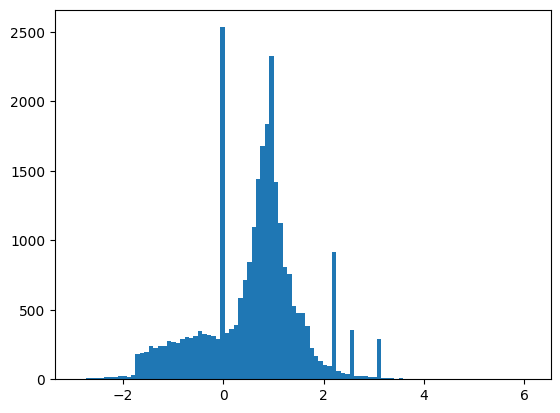

In [11]:
for features,label in packed_ds.batch(1000).take(1):
  print(features[0])
  plt.hist(features.numpy().flatten(), bins = 101)

In [12]:
N_VALIDATION = int(1e3)
N_TRAIN = int(1e4)
BUFFER_SIZE = int(1e4)
BATCH_SIZE = 500
STEPS_PER_EPOCH = int(N_TRAIN/BATCH_SIZE)

In [13]:
validate_ds = packed_ds.take(N_VALIDATION).cache()
train_ds = packed_ds.skip(N_VALIDATION).take(N_TRAIN).cache()

In [14]:
train_ds

<CacheDataset element_spec=(TensorSpec(shape=(28,), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.float32, name=None))>

In [15]:
validate_ds = validate_ds.batch(BATCH_SIZE)
train_ds = train_ds.shuffle(BUFFER_SIZE).repeat().batch(BATCH_SIZE)

In [16]:
print(validate_ds.counter)

<function DatasetV2.counter at 0x7b396afbdb20>


PRZYGOTOWANIE MODELU DO PREZENTACJI OVERFITTINGU

In [17]:
lr_schedule = tf.keras.optimizers.schedules.InverseTimeDecay(
    0.001,
    decay_steps = STEPS_PER_EPOCH*1000,
    decay_rate = 1,
    staircase=False
)

def get_optimizer():
  return tf.keras.optimizers.Adam(lr_schedule)

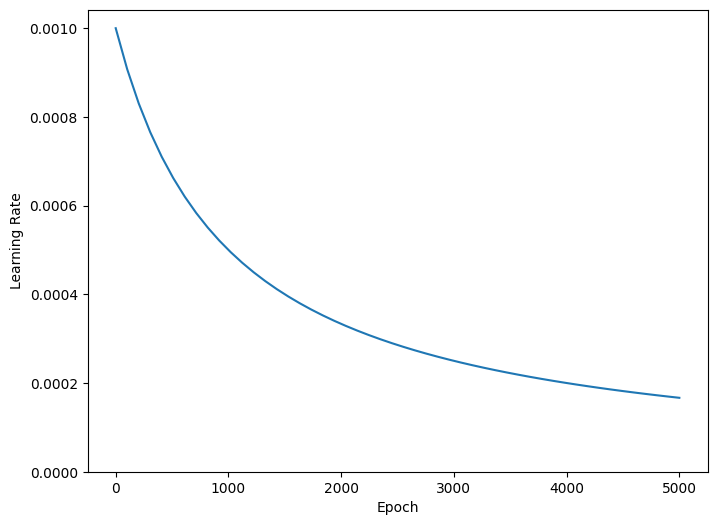

In [18]:
step = np.linspace(0,100_000)
lr = lr_schedule(step)
plt.figure(figsize=(8,6))
plt.plot(step/STEPS_PER_EPOCH,lr)
plt.ylim([0,max(plt.ylim())])
plt.xlabel('Epoch')
_ = plt.ylabel('Learning Rate')

In [19]:
def get_callbacks(name):
  return [
      tfdocs.modeling.EpochDots(),
      tf.keras.callbacks.EarlyStopping(monitor='val_binary_crossentropy', patience=200),
      tf.keras.callbacks.TensorBoard(logdir/name),
  ]

In [20]:
def compile_and_fit(model,name,optimizer=None,max_epochs = 10000):
  if optimizer is None:
    optimizer = get_optimizer()
  model.compile(optimizer = optimizer,
                loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                metrics=[
                    tf.keras.losses.BinaryCrossentropy(
                        from_logits=True, name='binary_crossentropy'
                    ),'accuracy'
                ])
  model.summary()
  history = model.fit(
      train_ds,
      steps_per_epoch = STEPS_PER_EPOCH,
      epochs = max_epochs,
      validation_data = validate_ds,
      callbacks = get_callbacks(name),
      verbose=0
  )
  return history

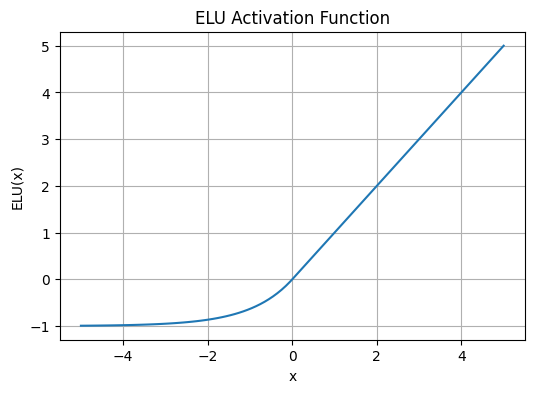

In [21]:
# prompt: narysuj funkcję elu

import matplotlib.pyplot as plt
import numpy as np
x = np.linspace(-5, 5, 100)
y_elu = tf.nn.elu(x)
plt.figure(figsize=(6, 4))
plt.plot(x, y_elu)
plt.title('ELU Activation Function')
plt.xlabel('x')
plt.ylabel('ELU(x)')
plt.grid(True)
plt.show()

BARDZO MAŁY MODEL -> tiny

In [22]:
from keras.src.metrics.confusion_metrics import activations
tiny_model = tf.keras.Sequential([
    layers.Dense(16,activation='elu',input_shape=(FEATURES,)),
    layers.Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
size_histories = {}

In [24]:
size_histories['Tiny'] = compile_and_fit(tiny_model,'sizes/Tiny')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 481 (1.88 KB)

 Trainable params: 481 (1.88 KB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.5079,  binary_crossentropy:0.9397,  loss:0.9397,  val_accuracy:0.4820,  val_binary_crossentropy:0.7596,  val_loss:0.7596,  
..

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


..................................................................................................
Epoch: 100, accuracy:0.5894,  binary_crossentropy:0.6323,  loss:0.6323,  val_accuracy:0.5620,  val_binary_crossentropy:0.6345,  val_loss:0.6345,  
....................................................................................................
Epoch: 200, accuracy:0.6090,  binary_crossentropy:0.6194,  loss:0.6194,  val_accuracy:0.6200,  val_binary_crossentropy:0.6195,  val_loss:0.6195,  
....................................................................................................
Epoch: 300, accuracy:0.6350,  binary_crossentropy:0.6107,  loss:0.6107,  val_accuracy:0.6210,  val_binary_crossentropy:0.6073,  val_loss:0.6073,  
....................................................................................................
Epoch: 400, accuracy:0.6416,  binary_crossentropy:0.6045,  loss:0.6045,  val_accuracy:0.6420,  val_binary_crossentropy:0.5984,  val_loss:0.5984,  
..........

In [25]:
print(size_histories)

{'Tiny': <keras.src.callbacks.history.History object at 0x7b3955c11550>}


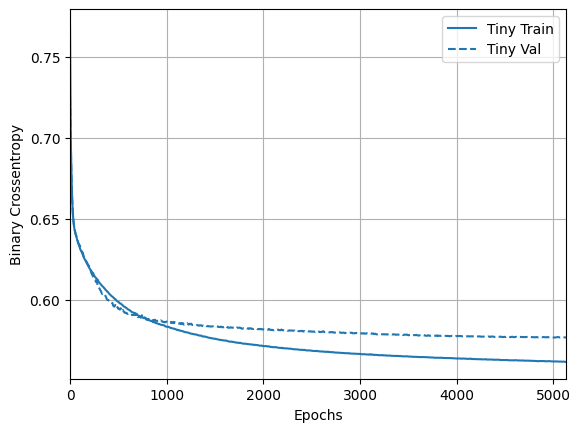

In [26]:
plotter = tfdocs.plots.HistoryPlotter(metric='binary_crossentropy',smoothing_std = 10)
plotter.plot(size_histories)
# plt.ylim([0.5,0.7])

MAŁY MODEL

In [27]:
small_model = tf.keras.Sequential([
    layers.Dense(16,activation='elu',input_shape=(FEATURES,)),
    layers.Dense(16,activation='elu'),
    layers.Dense(1)
])

In [28]:
size_histories['Small'] = compile_and_fit(small_model,'sizes/Small')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 753 (2.94 KB)

 Trainable params: 753 (2.94 KB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.5074,  binary_crossentropy:0.7450,  loss:0.7450,  val_accuracy:0.4820,  val_binary_crossentropy:0.7152,  val_loss:0.7152,  
....................................................................................................
Epoch: 100, accuracy:0.6294,  binary_crossentropy:0.6116,  loss:0.6116,  val_accuracy:0.6070,  val_binary_crossentropy:0.6127,  val_loss:0.6127,  
....................................................................................................
Epoch: 200, accuracy:0.6662,  binary_crossentropy:0.5839,  loss:0.5839,  val_accuracy:0.6490,  val_binary_crossentropy:0.5876,  val_loss:0.5876,  
....................................................................................................
Epoch: 300, accuracy:0.6834,  binary_crossentropy:0.5715,  loss:0.5715,  val_accuracy:0.6410,  val_binary_crossentropy:0.5916,  val_loss:0.5916,  
....................................................................................................
Epoch: 40

MODEL ŚREDNI -  medium



In [29]:
medium_model = tf.keras.Sequential([
    layers.Dense(64,activation='elu',input_shape=(FEATURES,)),
    layers.Dense(64,activation='elu'),
    layers.Dense(64,activation='elu'),
    layers.Dense(1)
])

In [30]:
size_histories['Medium'] = compile_and_fit(medium_model,'sizes/Medium')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,241 (40.00 KB)

 Trainable params: 10,241 (40.00 KB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.4974,  binary_crossentropy:0.6866,  loss:0.6866,  val_accuracy:0.4760,  val_binary_crossentropy:0.6791,  val_loss:0.6791,  
....................................................................................................
Epoch: 100, accuracy:0.7176,  binary_crossentropy:0.5275,  loss:0.5275,  val_accuracy:0.6450,  val_binary_crossentropy:0.6241,  val_loss:0.6241,  
....................................................................................................
Epoch: 200, accuracy:0.7876,  binary_crossentropy:0.4270,  loss:0.4270,  val_accuracy:0.6350,  val_binary_crossentropy:0.7026,  val_loss:0.7026,  
................................................................

DUZY MODEL - large

In [31]:
large_model = tf.keras.Sequential([
    layers.Dense(512,activation='elu',input_shape=(FEATURES,)),
    layers.Dense(512,activation='elu'),
    layers.Dense(512,activation='elu'),
    layers.Dense(512,activation='elu'),
    layers.Dense(1)
])

In [32]:
size_histories['Large'] = compile_and_fit(large_model,'sizes/Large')

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 512)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,329 (3.06 MB)

 Trainable params: 803,329 (3.06 MB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.5104,  binary_crossentropy:0.7741,  loss:0.7741,  val_accuracy:0.4980,  val_binary_crossentropy:0.6851,  val_loss:0.6851,  
....................................................................................................
Epoch: 100, accuracy:1.0000,  binary_crossentropy:0.0022,  loss:0.0022,  val_accuracy:0.6580,  val_binary_crossentropy:1.7248,  val_loss:1.7248,  
....................................................................................................
Epoch: 200, accuracy:1.0000,  binary_crossentropy:0.0001,  loss:0.0001,  val_accuracy:0.6560,  val_binary_crossentropy:2.3474,  val_loss:2.3474,  
...................

Text(0.5, 0, 'Epochs(log scale)')

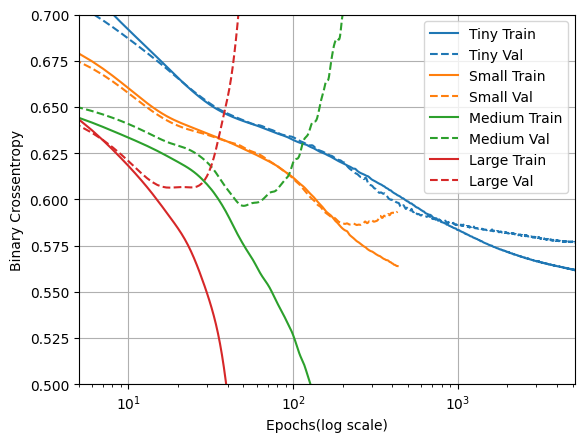

In [33]:
plotter.plot(size_histories)
a = plt.xscale('log')
plt.xlim([5,max(plt.xlim())])
plt.ylim([0.5,0.7])
plt.xlabel("Epochs(log scale)")

In [34]:
shutil.rmtree(logdir/'regularizers/Tiny', ignore_errors=True)
shutil.copytree(logdir/'sizes/Tiny', logdir/'regularizers/Tiny')

PosixPath('/tmp/tmprmm03qw2/tensorboard_logs/regularizers/Tiny')

In [35]:
regularizer_histories = {}
regularizer_histories['Tiny'] = size_histories['Tiny']

REGULARYZACJE WAGI!
DWA WARIANTY REGULARYZACJI WAG: L1, L2
L1 - koszt jest proporcjonalny do bezwzględnej wartości współczynników wag
L2 - koszt jest proporcjonalny do kwadratów wartości współczynników wag

In [36]:
l2_model = tf.keras.Sequential([
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.001),input_shape=(FEATURES,)),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.001)),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.001)),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.001)),
    layers.Dense(1)
])

regularizer_histories['l2'] = compile_and_fit(l2_model,"regularizers/l2")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 512)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,329 (3.06 MB)

 Trainable params: 803,329 (3.06 MB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.5025,  binary_crossentropy:0.8266,  loss:2.3455,  val_accuracy:0.4650,  val_binary_crossentropy:0.7167,  val_loss:2.1588,  
....................................................................................................
Epoch: 100, accuracy:0.6562,  binary_crossentropy:0.6009,  loss:0.6232,  val_accuracy:0.6180,  val_binary_crossentropy:0.5948,  val_loss:0.6169,  
....................................................................................................
Epoch: 200, accuracy:0.6718,  binary_crossentropy:0.5807,  loss:0.6030,  val_accuracy:0.6600,  val_binary_crossentropy:0.5854,  val_loss:0.6074,  
....................................................................................................
Epoch: 300, accuracy:0.6807,  binary_crossentropy:0.5782,  loss:0.6008,  val_accuracy:0.6900,  val_binary_crossentropy:0.5793,  val_loss:0.6019,  
....................................................................................................
Epoch: 40

(0.5, 0.7)

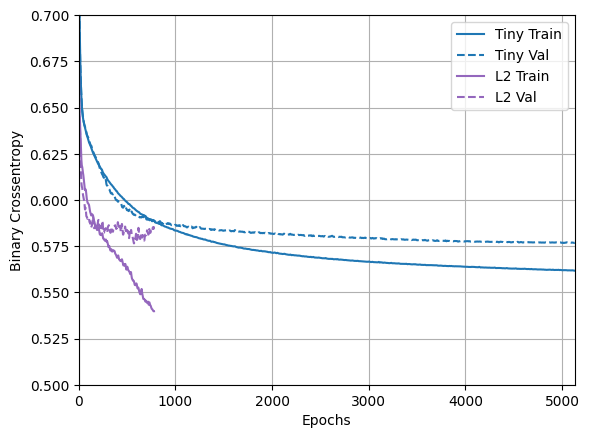

In [37]:
plotter.plot(regularizer_histories)
plt.ylim([0.5,0.7])

ingerencja w sieci przetrenowane - dropout (odrzucenie)

In [38]:
dropout_model = tf.keras.Sequential([
    layers.Dense(512,activation='elu',input_shape=(FEATURES,)),
    layers.Dropout(0.5),
    layers.Dense(512,activation='elu'),
    layers.Dropout(0.5),
    layers.Dense(512,activation='elu'),
    layers.Dropout(0.5),
    layers.Dense(512,activation='elu'),
    layers.Dropout(0.5),
    layers.Dense(1)
])

regularizer_histories['dropout'] = compile_and_fit(dropout_model,"regularizers/dropout")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 512)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,329 (3.06 MB)

 Trainable params: 803,329 (3.06 MB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.5103,  binary_crossentropy:0.7934,  loss:0.7934,  val_accuracy:0.5500,  val_binary_crossentropy:0.6872,  val_loss:0.6872,  
....................................................................................................
Epoch: 100, accuracy:0.6515,  binary_crossentropy:0.5966,  loss:0.5966,  val_accuracy:0.6890,  val_binary_crossentropy:0.5790,  val_loss:0.5790,  
....................................................................................................
Epoch: 200, accuracy:0.6910,  binary_crossentropy:0.5588,  loss:0.5588,  val_accuracy:0.6970,  val_binary_crossentropy:0.5874,  val_loss:0.5874,  
....................................................................................................
Epoch: 300, accuracy:0.7251,  binary_crossentropy:0.5121,  loss:0.5121,  val_accuracy:0.6680,  val_binary_crossentropy:0.5990,  val_loss:0.5990,  
...................................

(0.5, 0.7)

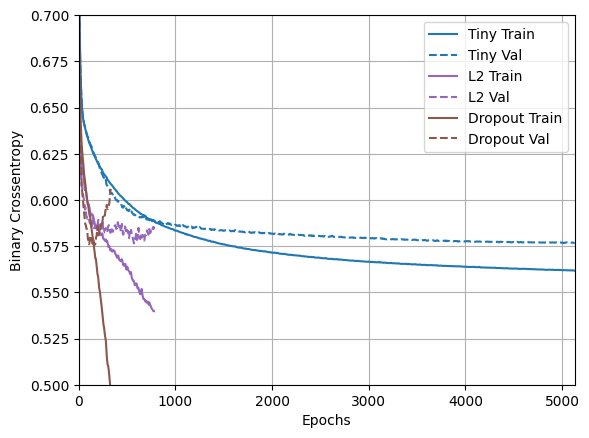

In [39]:
plotter.plot(regularizer_histories)
plt.ylim([0.5,0.7])

In [40]:
l2_model = tf.keras.Sequential([
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.01),input_shape=(FEATURES,)),
    layers.Dropout(0.3),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.01)),
    layers.Dropout(0.3),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.01)),
    layers.Dropout(0.3),
    layers.Dense(512,activation='elu',kernel_regularizer = regularizers.l2(0.01)),
    # Removed Reshape, Conv1D, and MaxPooling1D layers
    layers.Dense(1)
])

regularizer_histories['l2_drop'] = compile_and_fit(l2_model,"regularizers/l2_drop")

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 512)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,329 (3.06 MB)

 Trainable params: 803,329 (3.06 MB)

 Non-trainable params: 0 (0.00 B)


Epoch: 0, accuracy:0.4962,  binary_crossentropy:0.7153,  loss:12.7264,  val_accuracy:0.5400,  val_binary_crossentropy:0.6804,  val_loss:8.9508,  
....................................................................................................
Epoch: 100, accuracy:0.5561,  binary_crossentropy:0.6479,  loss:0.6721,  val_accuracy:0.5150,  val_binary_crossentropy:0.6484,  val_loss:0.6709,  
....................................................................................................
Epoch: 200, accuracy:0.5613,  binary_crossentropy:0.6460,  loss:0.6679,  val_accuracy:0.5770,  val_binary_crossentropy:0.6365,  val_loss:0.6600,  
....................................................................................................
Epoch: 300, accuracy:0.5709,  binary_crossentropy:0.6434,  loss:0.6645,  val_accuracy:0.5450,  val_binary_crossentropy:0.6379,  val_loss:0.6580,  
....................................................................................................
Epoch: 4

(0.5, 0.7)

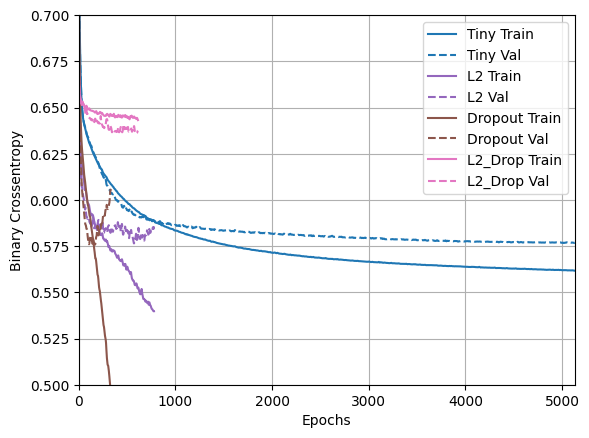

In [41]:
plotter.plot(regularizer_histories)
plt.ylim([0.5,0.7])

OPTYMALIZACJA MODELU LARGE -> Large_OPT

**Cel:** zjechać z błędem walidacyjnym (`val_binary_crossentropy`) modelu Large (4 × Dense 512, ELU) jak najniżej, zachowując jego architekturę.

**Wybrana konfiguracja (Large_OPT):** standaryzacja + szum 0,1 + dropout 0,5 + L2 1e-4, a do tego wczesne zatrzymanie z przywróceniem najlepszych wag (`restore_best_weights=True`).

Dlaczego to działa:
- **Standaryzacja wejścia** (warstwa `Normalization`, statystyki liczone tylko na treningu) – cechy HIGGS mają różne skale (0…13), a ELU i Adam najlepiej pracują na danych o średniej 0 i wariancji 1. To dało największy pojedynczy zysk.
- **GaussianNoise(0,1)** na wejściu – działa jak augmentacja danych: sieć nie może zapamiętać dokładnych wartości cech.
- **Dropout 0,5 + L2 1e-4** na każdej warstwie ukrytej – hamuje zapamiętywanie zbioru treningowego przez 800 tys. parametrów.
- **restore_best_weights** – po zatrzymaniu model wraca do epoki z najniższym błędem walidacyjnym, a nie zostaje z wagami z końca treningu.

### Log eksperymentu (poza Colabem)
UCI był niedostępny z mojego środowiska, więc eksperyment liczyłem na pierwszych 7500 wierszach HIGGS (z repozytorium microsoft/LightGBM): walidacja = wiersze 1–1000 (te same co tutaj), trening = 5000 wierszy, test = 1500 odłożonych wierszy. Protokół (kryteria sukcesu) zapisano przed obliczeniami.

**Etap 1 – wybór techniki na walidacji** (min val BCE; dla top-3 średnia z 2 seedów):

| wariant | val BCE (seed 0) | średnia |
|---|---|---|
| standaryzacja + szum 0,1 + dropout 0,5 + L2 1e-4 | 0.5648 | 0.5614 |
| standaryzacja + dropout 0,5 | 0.5654 | 0.5657 |
| dropout 0,5 + L2 1e-4 | 0.5899 | 0.5883 |
| L2 1e-3 | 0.5937 | 0.5937 |
| label smoothing 0,05 + dropout 0,5 | 0.5949 | 0.5949 |
| AdamW + dropout 0,5 | 0.5982 | 0.5982 |
| dropout 0,5 | 0.5982 | 0.5982 |
| ReduceLROnPlateau + dropout 0,5 | 0.5988 | 0.5988 |
| BatchNorm + dropout 0,3 | 0.6022 | 0.6022 |
| dropout 0,3 | 0.6036 | 0.6036 |
| szum gaussowski 0,1 + dropout 0,5 | 0.6047 | 0.6047 |
| Large (bez regularyzacji) | 0.6141 | 0.6141 |
| L2 1e-4 | 0.6151 | 0.6151 |

**Etap 2 – weryfikacja na odłożonym teście** (5 nowych seedów):

| model | test BCE (średnia ± sd) | accuracy | AUC |
|---|---|---|---|
| Large OPT (KS) | 0.5714 ± 0.0034 | 0.704 | 0.771 |
| Large + ES (restore best) | 0.6258 ± 0.0041 | 0.659 | 0.715 |
| Tiny | 0.6296 ± 0.0079 | 0.657 | 0.709 |
| Large bez restore (ostatnia epoka) | 2.5281 ± 0.0469 | 0.625 | 0.670 |
| Tiny + standaryzacja | 0.6103 ± 0.0062 | 0.675 | 0.735 |
| HistGradientBoosting | 0.5443 ± 0.0000 | 0.725 | 0.803 |
| Ensemble 5× KS | 0.5676 ± 0.0000 | 0.703 | 0.774 |

Parowane porównania test BCE (5 seedów): Large_OPT vs Large+ES: różnica -0.0544, wygrane 5/5, p (Holm) = 5.36e-05; Large_OPT vs Tiny: różnica -0.0583, wygrane 5/5, p (Holm) = 5.36e-05. Werdykt wg protokołu: **SUKCES**. Opisowo, vs Tiny ze standaryzacją: różnica -0.0389, wygrane 5/5.

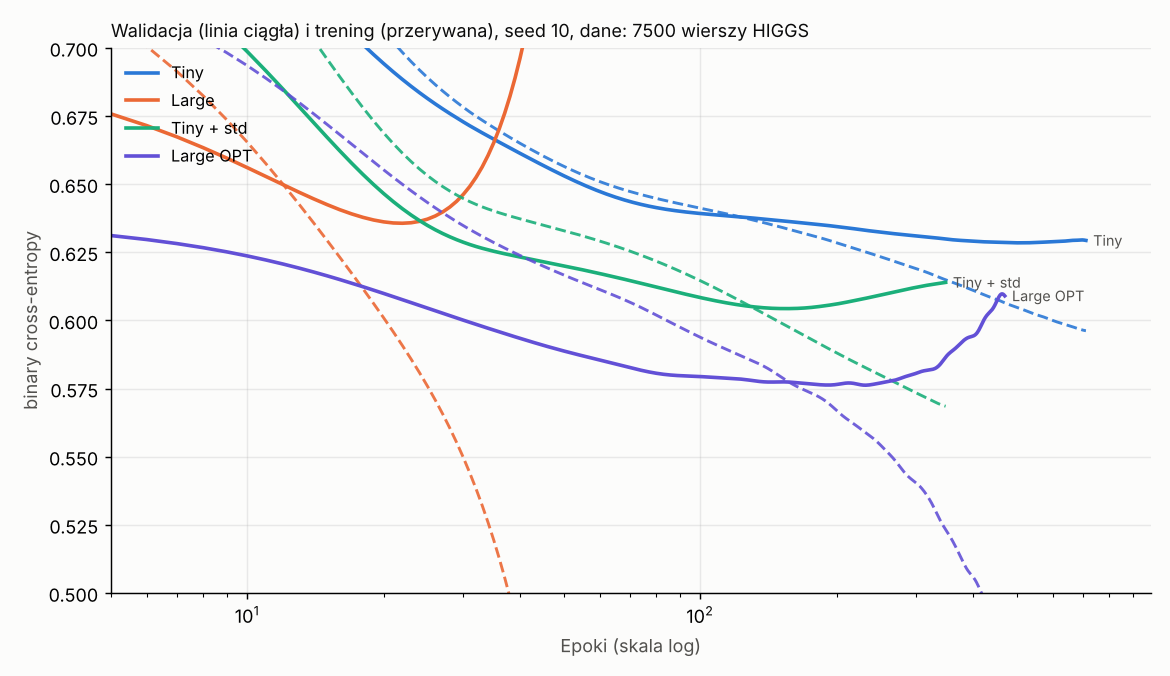

Poniższe komórki trenują Large_OPT na pełnych danych z tego notebooka (10 000 wierszy treningu) i dokładają go do obu wykresów.

In [ ]:
# Standaryzacja wejścia: średnia i wariancja liczone WYŁĄCZNIE na zbiorze treningowym (bez wycieku z walidacji)
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(packed_ds.skip(N_VALIDATION).take(N_TRAIN).map(lambda x, y: x).batch(BATCH_SIZE))
print('średnie cech:', normalizer.mean.numpy().round(3))
print('odchylenia  :', np.sqrt(normalizer.variance.numpy()).round(3))

In [ ]:
def build_large_opt():
  reg = regularizers.l2(1e-4)
  return tf.keras.Sequential([
      layers.Input(shape=(FEATURES,)),
      normalizer,                       # standaryzacja wejścia
      layers.GaussianNoise(0.1),        # szum na wejściu (augmentacja, aktywny tylko w treningu)
      layers.Dense(512, activation='elu', kernel_regularizer=reg),
      layers.Dropout(0.5),
      layers.Dense(512, activation='elu', kernel_regularizer=reg),
      layers.Dropout(0.5),
      layers.Dense(512, activation='elu', kernel_regularizer=reg),
      layers.Dropout(0.5),
      layers.Dense(512, activation='elu', kernel_regularizer=reg),
      layers.Dropout(0.5),
      layers.Dense(1)
  ], name='large_opt')

def compile_and_fit_opt(model, name, max_epochs=10000):
  # jak compile_and_fit, ale EarlyStopping przywraca wagi z najlepszej epoki walidacyjnej
  model.compile(optimizer=get_optimizer(),
                loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
                metrics=[tf.keras.losses.BinaryCrossentropy(from_logits=True, name='binary_crossentropy'), 'accuracy'])
  model.summary()
  callbacks = [
      tfdocs.modeling.EpochDots(),
      tf.keras.callbacks.EarlyStopping(monitor='val_binary_crossentropy', patience=200, restore_best_weights=True),
      tf.keras.callbacks.TensorBoard(logdir/name),
  ]
  return model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=max_epochs,
                   validation_data=validate_ds, callbacks=callbacks, verbose=0)

large_opt_model = build_large_opt()

In [ ]:
size_histories['Large_OPT'] = compile_and_fit_opt(large_opt_model, 'sizes/Large_OPT')
regularizer_histories['Large_OPT'] = size_histories['Large_OPT']

WYKRES: ROZMIARY MODELI + Large_OPT

In [ ]:
plotter.plot(size_histories)
plt.xscale('log')
plt.xlim([5, max(plt.xlim())])
plt.ylim([0.5, 0.7])
plt.xlabel('Epochs (log scale)')
plt.title('Tiny / Small / Medium / Large vs Large_OPT')

WYKRES: REGULARYZACJE + Large_OPT

In [ ]:
plotter.plot(regularizer_histories)
plt.ylim([0.5, 0.7])
plt.title('Regularyzacje vs Large_OPT')

PODSUMOWANIE: najniższy błąd walidacyjny każdego modelu

In [ ]:
import pandas as pd
rows = []
for name, h in {**size_histories, **regularizer_histories}.items():
  v = h.history['val_binary_crossentropy']; t = h.history['binary_crossentropy']
  i = int(np.argmin(v))
  rows.append(dict(model=name, min_val_bce=round(v[i], 4), best_epoch=i, train_bce_at_best=round(t[i], 4),
                   last_val_bce=round(v[-1], 4), epochs=len(v)))
summary = pd.DataFrame(rows).drop_duplicates('model').sort_values('min_val_bce').reset_index(drop=True)
summary

In [ ]:
# Large_OPT ma przywrócone wagi z najlepszej epoki – sprawdzenie na walidacji
large_opt_model.evaluate(validate_ds, return_dict=True, verbose=0)